# 3. Quatre modèles supervisés candidats et choix du meilleur

| Modèle | Type | Pourquoi lui |
| --- | --- | --- |
| Random Forest | supervisé | apprend sur des attaques étiquetées ; robuste, explicable avec SHAP |
| XGBoost | supervisé | boosting, souvent le plus précis sur des données tabulaires ; explicable avec SHAP |
| Régression Logistique | supervisé | baseline **linéaire** simple et interprétable ; sert de point de comparaison (les arbres devraient la dépasser) |
| MLP | supervisé | réseau de neurones ; apporte une famille **non-arbre** au comparatif |

**Protocole.** Les quatre modèles apprennent sur les lignes des blocs d'entraînement
(normales **et** attaques, ~33 %). Validation et test sont à une proportion **réaliste**
(≈ 13–15 % d'attaques). Deux seuils d'alerte par modèle, tous deux choisis sur la **validation**
puis appliqués tels quels au **test** :

- **max F1** : le seuil qui maximise le F1 de validation ;
- **rappel cible** (0,90 par défaut) : le seuil le plus haut qui attrape au moins 90 % des mesures
  falsifiées de la validation. C'est le mode **« rappel d'abord »** : rater une attaque coûte plus
  cher (lots perdus, patient) qu'une fausse alerte.

Le **choix du modèle** se fait sur la **validation** (F2, qui donne au rappel 4 fois le poids de la
précision) ; le test ne fait que **confirmer**.

**Déséquilibre des classes.** Poids de classe (`class_weight`, `scale_pos_weight`, `sample_weight`),
**pas de SMOTE** : sur une série temporelle, des points synthétiques interpolés entre deux lignes
d'attaque fabriqueraient des fenêtres glissantes qui n'existent pas, et le sur-échantillonnage ne
change pas la proportion d'attaques du test, qui seule fixe la précision réelle. Le vrai levier
est le **seuil**.

Ordre des métriques partout : **rappel, fausses alertes/heure, délai de détection, précision, F1/F2**.

> Les modèles **non supervisés** (Isolation Forest, One-Class SVM) et la référence
> statistique ont été **retirés** : le comparatif ne porte que sur des modèles supervisés.

In [1]:
%%capture
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "backend").is_dir())
sys.path[:0] = [str(ROOT / "backend"), str(ROOT / "backend" / "scripts")]
import build_dataset as bd
import transmission_real as tr
import transmission_models as tm
import transmission_study as ts
from app.api.v1 import phase2
from app.core import paths

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (11, 3.5)
SEED = tr.SEED
COLS = {"weather": "temperature", "fridge": "fridge_temperature", "thermostat": "current_temperature"}
EPISODES_PATH = paths.PROCESSED_DIR / "episodes_transmission_reel.json"
MODEL_DIR = paths.MODELS_DIR / "transmission_reel"

In [2]:
df = pd.read_csv(tr.DATASET_PATH, parse_dates=["datetime"], keep_default_na=False)
df["garde"] = df["garde"].astype(str).str.lower().eq("true")
df, feats = tm.engineer(df)
episodes = json.load(open(EPISODES_PATH))

y = df["label"].to_numpy().astype(int)
# Le découpage train/val/test n'est pas dans le dataset : on le calcule ICI, à
# l'entraînement, de façon NON aléatoire (70/15/15 par blocs d'une heure).
split = tr.block_split(len(df), run=0)
garde = df["garde"].to_numpy()
train_all = np.where((split == "train") & ~garde)[0]
train_norm = train_all[y[train_all] == 0]
val_idx = np.where((split == "val") & ~garde)[0]
test_idx = np.where((split == "test") & ~garde)[0]
X = df[feats].to_numpy(float)
from sklearn.preprocessing import StandardScaler
X_s = StandardScaler().fit(X[train_norm]).transform(X)
print(f"train {len(train_all):,} lignes ({len(train_norm):,} normales) | val {len(val_idx):,} | test {len(test_idx):,}")


train 28,903 lignes (18,725 normales) | val 6,254 | test 6,226


## 3.0 Validation croisée : d'abord la version naïve (ce qu'il ne faut PAS faire)

- `cross_validate` fait passer au modèle **5 examens** (5 folds) : 4 morceaux pour apprendre,
  1 pour noter, en tournant → 5 notes, dont on retient la **moyenne** et l'**écart-type**.
- `StratifiedKFold` (le **stratify**) garantit que chaque fold garde le même % d'attaques (~33 % au train).
- On note le **rappel** et la **précision** (et le F1), jamais l'accuracy : un modèle qui crierait
  « normal » à tout le temps aurait ~**67 %** d'accuracy sur ces lignes d'entraînement.
- **Attention** : ici les lignes sont **mélangées au hasard**. On garde ce calcul uniquement pour
  montrer le piège (fuite), la section suivante fait la version honnête.

In [3]:
# ===== VALIDATION CROISÉE NAÏVE : 5 EXAMENS AU LIEU D'UN (à ne pas faire) =====
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)  # "stratify", lignes MÉLANGÉES

X_tr, y_tr = X[train_all], y[train_all]
pos_tr = int(y_tr.sum())
# MLP n'a pas de class_weight : on équilibre les classes à la main (même logique)
poids_tr = np.where(y_tr == 1, len(y_tr) / (2 * pos_tr), len(y_tr) / (2 * (len(y_tr) - pos_tr)))

# Mêmes réglages que transmission_models.py ; n_jobs = 3 cœurs au plus (serveur partagé)
modeles_cv = {
    "Régression Logistique": (LogisticRegression(max_iter=1000, class_weight="balanced",
                                                 random_state=SEED), X_s, None),
    "Random Forest": (RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                             class_weight="balanced_subsample",
                                             random_state=SEED, n_jobs=tm.N_JOBS), X, None),
    "XGBoost": (XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.05, subsample=0.8,
                              colsample_bytree=0.8, scale_pos_weight=(len(y_tr) - pos_tr) / pos_tr,
                              eval_metric="logloss", random_state=SEED, n_jobs=tm.N_JOBS, verbosity=0), X, None),
    "MLP": (MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, early_stopping=True,
                          random_state=SEED), X_s, {"sample_weight": poids_tr}),
}
scoring = ["recall", "precision", "f1"]

cv_naif = {}
for nom, (mod, Xm, params) in modeles_cv.items():
    notes = cross_validate(mod, Xm[train_all], y_tr, cv=cv, scoring=scoring, params=params)
    cv_naif[nom] = notes
    print(f"{nom:<22} rappel {notes['test_recall'].mean():.3f} +/- {notes['test_recall'].std():.3f}   "
          f"précision {notes['test_precision'].mean():.3f} +/- {notes['test_precision'].std():.3f}")

Régression Logistique  rappel 0.691 +/- 0.012   précision 0.630 +/- 0.006


Random Forest          rappel 0.983 +/- 0.003   précision 0.994 +/- 0.002


XGBoost                rappel 0.991 +/- 0.002   précision 0.997 +/- 0.001


MLP                    rappel 0.985 +/- 0.003   précision 0.985 +/- 0.002


## 3.0bis Validation croisée honnête (groupée par BLOC d'une heure) — la confirmation

**Le problème.** Nos attaques durent 15 à 25 minutes. À 5 secondes par mesure, cela fait
beaucoup de lignes presque identiques. Avec un découpage **au hasard** (`StratifiedKFold`),
une partie de la **même attaque** tombe dans le train *et* dans le test : le modèle la
**reconnaît** et obtient un score de ~0,99. C'est un score **trop beau** (fuite temporelle).
Et ce n'est pas seulement l'attaque : les **lignes normales** qui l'entourent partagent ses
**fenêtres glissantes** (moyennes et écarts-types sur 1, 5 et 15 min) ; elles « portent » une
trace de l'attaque.

**L'image.** C'est comme réviser avec *exactement* les questions de l'examen : on a 20/20
sans rien prouver.

**La solution.** Le **groupe = le bloc d'une heure** (`tr.block_index`). Chaque attaque tient
dans un bloc, et les lignes normales qui partagent ses fenêtres sont dans le même bloc : avec
`StratifiedGroupKFold`, un bloc est **entièrement** d'un seul côté. C'est exactement l'unité du
protocole train/val/test. Cette validation croisée **confirme** le protocole par blocs, elle ne le
remplace pas (elle n'utilise que les lignes d'entraînement de la répétition 0, au seuil 0,5).

In [4]:
# ===== VALIDATION CROISÉE HONNÊTE (groupe = bloc d'une heure) =====
from sklearn.model_selection import StratifiedGroupKFold

# 1) Le groupe de chaque ligne = son bloc d'une heure (le même découpage que train/val/test)
groups = tr.block_index(len(df))
groups_train = groups[train_all]
print(f"Groupes : {len(np.unique(groups_train))} blocs d'une heure dans les lignes d'entraînement")

# 2) Stratified (garde le % d'attaques) + Group (un bloc entier d'un seul côté)
cv_groupes = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
print(f"Blocs présents des deux côtés d'un fold : naïf {tm.shared_blocks(cv, X_tr, y_tr, groups_train)}, "
      f"groupé {tm.shared_blocks(cv_groupes, X_tr, y_tr, groups_train)}")

rows = []
for nom, (mod, Xm, params) in modeles_cv.items():
    h = cross_validate(mod, Xm[train_all], y_tr, cv=cv_groupes, groups=groups_train, scoring=scoring, params=params)
    n = cv_naif[nom]
    rows.append({"modèle": nom,
                 "rappel groupé": f"{h['test_recall'].mean():.3f} ± {h['test_recall'].std():.3f}",
                 "précision groupée": f"{h['test_precision'].mean():.3f} ± {h['test_precision'].std():.3f}",
                 "F1 groupé": f"{h['test_f1'].mean():.3f} ± {h['test_f1'].std():.3f}",
                 "rappel naïf": f"{n['test_recall'].mean():.3f} ± {n['test_recall'].std():.3f}",
                 "précision naïve": f"{n['test_precision'].mean():.3f} ± {n['test_precision'].std():.3f}"})
display(pd.DataFrame(rows).set_index("modèle"))
print("À retenir : la version groupée par bloc donne un score plus bas mais VRAI ;")
print("la version naïve est gonflée par la fuite (même attaque et mêmes fenêtres des deux côtés).")

Groupes : 44 blocs d'une heure dans les lignes d'entraînement
Blocs présents des deux côtés d'un fold : naïf 220, groupé 0


,rappel groupé,précision groupée,F1 groupé,rappel naïf,précision naïve
modèle,,,,,
Régression Logistique,0.613 ± 0.078,0.584 ± 0.068,0.597 ± 0.065,0.691 ± 0.012,0.630 ± 0.006
Random Forest,0.622 ± 0.101,0.863 ± 0.064,0.716 ± 0.074,0.983 ± 0.003,0.994 ± 0.002
XGBoost,0.539 ± 0.110,0.751 ± 0.063,0.624 ± 0.095,0.991 ± 0.002,0.997 ± 0.001
MLP,0.542 ± 0.047,0.623 ± 0.105,0.578 ± 0.072,0.985 ± 0.003,0.985 ± 0.002


À retenir : la version groupée par bloc donne un score plus bas mais VRAI ;
la version naïve est gonflée par la fuite (même attaque et mêmes fenêtres des deux côtés).


## 3.1 Entraînement des modèles supervisés

Ce que cette cellule NE fait PAS

❌ Elle ne choisit pas le seuil. 

❌ Elle ne compare pas les modèles. 

❌ Elle ne donne pas de résultat final.

Elle fait une seule chose : entraîner + calculer les scores.


In [5]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

scores = {}

# --- Random Forest (supervisé : a appris sur des attaques étiquetées) ---
# n_estimators=300                : 300 arbres votent (vote majoritaire)
# min_samples_leaf=5              : une conclusion doit reposer sur >= 5 exemples (évite le surapprentissage)
# class_weight=balanced_subsample : les attaques sont moins nombreuses -> on leur donne plus de poids
# random_state=SEED               : on fixe le hasard
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample",
                            random_state=SEED, n_jobs=tm.N_JOBS).fit(X[train_all], y[train_all])
scores["Random Forest"] = rf.predict_proba(X)[:, 1]           # % d'arbres qui votent attaque (0 à 1)

# --- XGBoost (supervisé : les arbres corrigent les erreurs des précédents) ---
# n_estimators=400       : 400 arbres en série (chaque arbre corrige le précédent)
# max_depth=6            : au plus 6 questions enchaînées par arbre
# learning_rate=0.05     : chaque arbre ne corrige que 5% de l'erreur -> apprentissage prudent
# subsample=0.8          : chaque arbre voit 80% des lignes au hasard -> diversité
# colsample_bytree=0.8   : chaque arbre voit 80% des colonnes (capteurs) au hasard -> diversité
# scale_pos_weight=...   : les attaques sont moins nombreuses -> on leur donne plus de poids
pos = int(y[train_all].sum())
xgb = XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                    scale_pos_weight=(len(train_all) - pos) / pos, eval_metric="logloss",
                    random_state=SEED, n_jobs=tm.N_JOBS, verbosity=0).fit(X[train_all], y[train_all])
scores["XGBoost"] = xgb.predict_proba(X)[:, 1]                 # probabilité d'attaque (0 à 1)
print("2 modèles supervisés entraînés (les 2 autres arrivent juste après)")

# ===== AFFICHER LE SCORE DE CHAQUE MODÈLE =====
from IPython.display import display

# Les 8 premiers scores de chaque modèle, côte à côte
apercu = pd.DataFrame({nom: np.round(s[:8], 4) for nom, s in scores.items()})
apercu.index.name = "ligne"
display(apercu)

# Le résumé de l'échelle de chaque modèle
resume = pd.DataFrame({nom: {"minimum": round(s.min(), 4),
                             "maximum": round(s.max(), 4),
                             "moyenne": round(s.mean(), 4)}
                       for nom, s in scores.items()})
display(resume)

2 modèles supervisés entraînés (les 2 autres arrivent juste après)


,Random Forest,XGBoost
ligne,,
0,0.5848,0.0873
1,0.4809,0.0047
2,0.4312,0.0109
3,0.4235,0.0104
4,0.3382,0.0818
5,0.3521,0.0630
6,0.1731,0.0089
7,0.1110,0.0075


,Random Forest,XGBoost
minimum,0.0000,0.0001
maximum,1.0000,1.0000
moyenne,0.3369,0.3219


### 2 nouveaux modèles supervisés (protocole identique aux autres)

- **Régression Logistique** : baseline **linéaire interprétable** (les arbres devraient la dépasser
  car la frontière normal/attaque n'est pas droite → c'est le rôle d'un baseline).
- **MLP** (réseau de neurones) : apporte une famille non-arbre au comparatif.
- On obtient au final **4 modèles supervisés** comparés sur le même protocole.


In [6]:
# --- Régression Logistique (linéaire, interprétable) ---
# X_s (standardisé) est obligatoire pour les modèles linéaires et les neurones
lr = LogisticRegression(max_iter=1000, class_weight="balanced",
                        random_state=SEED).fit(X_s[train_all], y[train_all])
scores["Régression Logistique"] = lr.predict_proba(X_s)[:, 1]

# --- MLP (réseau de neurones) ---
# early_stopping=True : arrête quand la progression s'arrête (anti-surapprentissage)
# sample_weight=poids_tr : équilibre attaques/normales (MLP n'a pas de class_weight)
mlp = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, early_stopping=True,
                    random_state=SEED).fit(X_s[train_all], y[train_all], sample_weight=poids_tr)
scores["MLP"] = mlp.predict_proba(X_s)[:, 1]

print("Modeles dans scores :", list(scores))

Modeles dans scores : ['Random Forest', 'XGBoost', 'Régression Logistique', 'MLP']


## 3.2 Évaluation (répétition 0) : deux seuils, choisis sur la validation

Pour chaque modèle, deux seuils sont choisis sur la **validation** (jamais sur le test) :
le **max F1**, et le seuil du **rappel cible** (`tm.threshold_for_recall`, 90 % par défaut).
Puis on fait passer l'examen (test). Tableau : rappel, fausses alertes/h, délai, épisodes,
précision, F1, F2 — sur la validation et sur le test.

In [7]:
# Outils de mesure pour noter les modèles (AUC, etc.)
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve

CIBLE = tm.TARGET_RECALL       # rappel visé sur la validation (0,90)
# rows = une ligne de résultats par modèle, seuil et rôle ; preds = décisions au seuil « rappel cible »
rows, preds, preds_f1, seuils = [], {}, {}, {}

for nom, s in scores.items():          # on passe en revue les 4 modèles, un par un
    # 1) Les seuils sont cherchés sur la VALIDATION (jamais sur le test !)
    s_f1 = phase2._best_f1_threshold(y[val_idx], s[val_idx])
    s_rc = tm.threshold_for_recall(y[val_idx], s[val_idx], CIBLE)
    seuils[nom] = {"max F1": s_f1, f"rappel {CIBLE:.2f}": s_rc}
    preds_f1[nom], preds[nom] = s >= s_f1, s >= s_rc
    # 2) On compte les bons coups et les erreurs, sur la validation et sur le TEST
    for nom_seuil, pred in ((f"rappel {CIBLE:.2f}", preds[nom]), ("max F1", preds_f1[nom])):
        for role, idx in (("val", val_idx), ("test", test_idx)):
            r = tr.pool([tr.count_run(pred, df, idx, episodes, role)])
            rows.append({"modèle": nom, "seuil": nom_seuil, "rôle": role,
                         "rappel": r["recall"],                                        # attaques attrapées
                         "fausses alertes / h": r["fausses_alarmes_evenements_par_heure"],   # plus bas = mieux
                         "délai médian (min)": r["delai_median_min"],                  # temps de réaction
                         "épisodes détectés": f"{r['episodes_detectes']}/{r['episodes']}",
                         "précision": r["precision"],                                  # quand j'alerte, ai-je raison ?
                         "F1": r["f1"], "F2": r["f2"]})
    print(f"{nom:<22} AUC test {roc_auc_score(y[test_idx], s[test_idx]):.3f}")
# On affiche le tout dans un tableau
pd.DataFrame(rows).set_index(["modèle", "seuil", "rôle"])

Random Forest          AUC test 0.795
XGBoost                AUC test 0.813
Régression Logistique  AUC test 0.746


MLP                    AUC test 0.756


rappel  fausses alertes / h  \
modèle                seuil       rôle                                
Random Forest         rappel 0.90 val   0.9009                18.67   
                                  test  0.7850                19.97   
                      max F1      val   0.6056                 2.06   
                                  test  0.6251                 0.98   
XGBoost               rappel 0.90 val   0.9009                23.34   
                                  test  0.8121                17.02   
                      max F1      val   0.5976                 4.80   
                                  test  0.5068                 1.97   
Régression Logistique rappel 0.90 val   0.9009                 0.82   
                                  test  1.0000                 0.98   
                      max F1      val   0.3568                 7.69   
                                  test  0.4282                 8.44   
MLP                   rappel 0.90 val   0.9009                14.83   
                                  test  0.9440                18.71   
                      max F1      val   0.4073                 4.39   
                                  test  0.3902                 4.08   

                                        délai médian (min) épisodes détectés  \
modèle                seuil       rôle                                         
Random Forest         rappel 0.90 val                  0.0               4/4   
                                  test                 0.5               4/4   
                      max F1      val                  2.3               4/4   
                                  test                 6.2               4/4   
XGBoost               rappel 0.90 val                  0.0               4/4   
                                  test                 0.7               4/4   
                      max F1      val                  2.2               4/4   
                                  test                 6.5               4/4   
Régression Logistique rappel 0.90 val                  0.0               4/4   
                                  test                 0.0               4/4   
                      max F1      val                  1.4               3/4   
                                  test                 6.8               4/4   
MLP                   rappel 0.90 val                  0.0               4/4   
                                  test                 0.0               4/4   
                      max F1      val                  4.9               4/4   
                                  test                 7.4               3/4   

                                        précision      F1      F2  
modèle                seuil       rôle                             
Random Forest         rappel 0.90 val      0.2267  0.3623  0.5649  
                                  test     0.2219  0.3460  0.5207  
                      max F1      val      0.9328  0.7344  0.6512  
                                  test     0.9624  0.7579  0.6722  
XGBoost               rappel 0.90 val      0.2087  0.3389  0.5417  
                                  test     0.2346  0.3640  0.5442  
                      max F1      val      0.8127  0.6887  0.6310  
                                  test     0.8487  0.6346  0.5512  
Régression Logistique rappel 0.90 val      0.1477  0.2538  0.4460  
                                  test     0.1778  0.3019  0.5195  
                      max F1      val      0.6040  0.4486  0.3886  
                                  test     0.4558  0.4415  0.4334  
MLP                   rappel 0.90 val      0.1623  0.2751  0.4717  
                                  test     0.1958  0.3244  0.5351  
                      max F1      val      0.7236  0.5212  0.4464  
                                  test     0.6180  0.4784  0.4213

### Matrice de confusion — à quoi ça sert ?


montre où le modèle se trompe (fausses alertes vs attaques ratées). 

La matrice de confusion est un **tableau 2×2** qui compare la **prédiction** du modèle et la **vraie réponse** :

|  | le modèle dit *attaque* | le modèle dit *normal* |
| --- | --- | --- |
| c'est vraiment une attaque | **Vrai positif** : attaque bien détectée | **Faux négatif** : attaque ratée (le pire !) |
| c'est vraiment normal | **Faux positif** : fausse alerte | **Vrai négatif** : normal reconnu |

- **Précision** = Vrai positif / (Vrai positif + Faux positif) → « quand j'alerte, est-ce que j'ai raison ? »
- **Rappel** = Vrai positif / (Vrai positif + Faux négatif) → « sur toutes les attaques, combien en ai-je trouvées ? »

On la regarde pour comprendre **où** le modèle se trompe : trop de fausses alertes, ou au contraire des attaques
qu'il laisse passer. Un seul chiffre comme le F1 ne donne que la note finale, pas le type d'erreur.

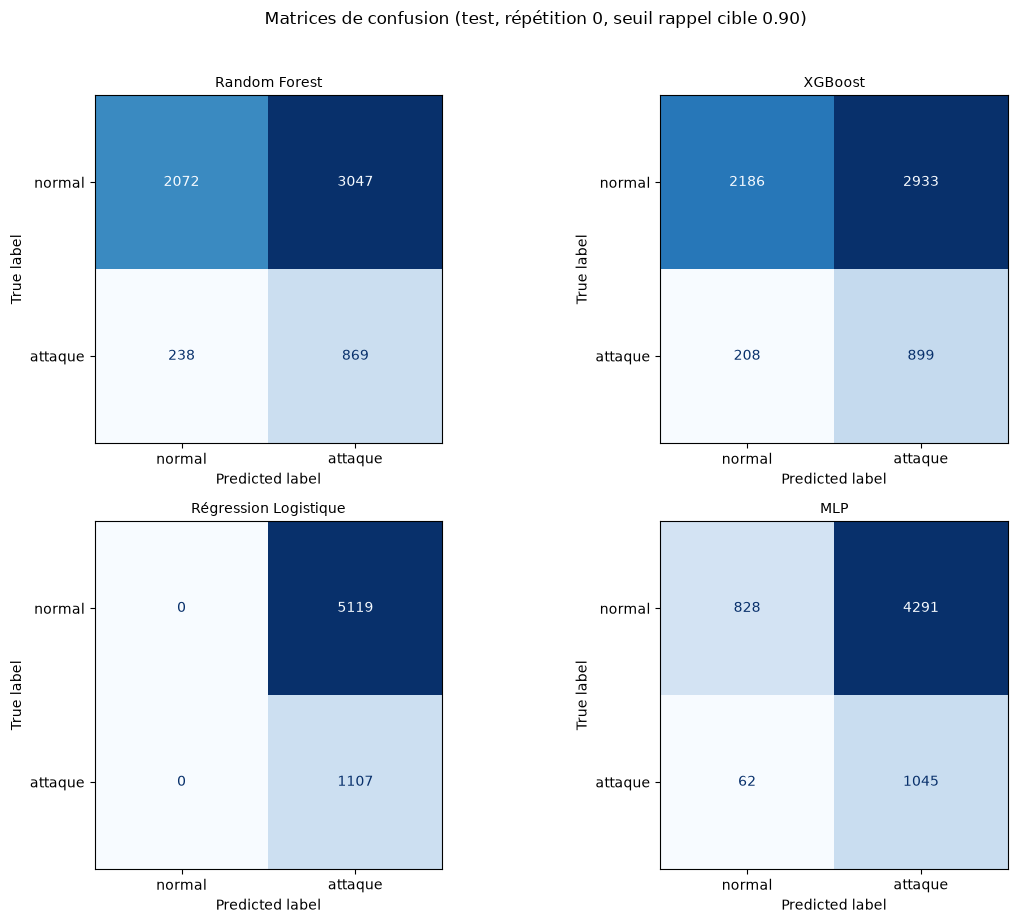

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

if "preds" not in dir():   # cellule exécutée seule : il faut d'abord avoir lancé le notebook plus haut
    raise NameError("Exécute d'abord les cellules 3.1 et 3.2 (les données, les modèles et le tableau de résultats), puis relance cette cellule.")

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, (nom, pred) in zip(axes.ravel(), preds.items()):
    cm = confusion_matrix(y[test_idx], pred[test_idx])
    ConfusionMatrixDisplay(cm, display_labels=["normal", "attaque"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(nom, fontsize=10)
plt.suptitle(f"Matrices de confusion (test, répétition 0, seuil rappel cible {CIBLE:.2f})", y=1.02, fontsize=12)
plt.tight_layout()
plt.show()

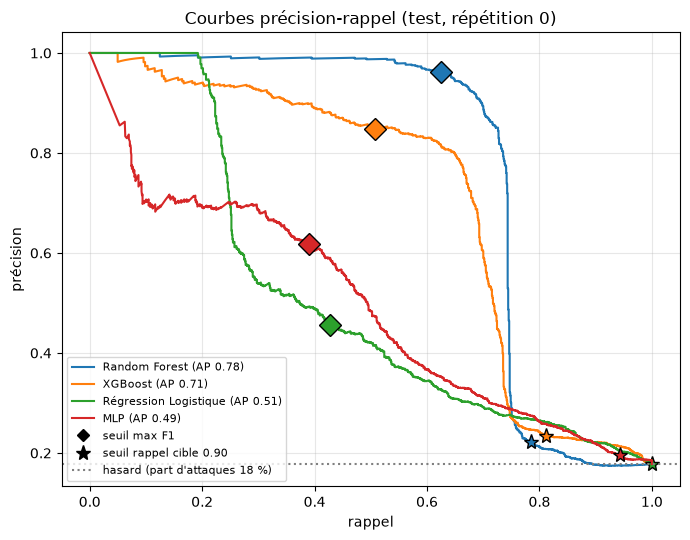

In [9]:
# Courbes précision-rappel du test ; les deux seuils (choisis sur la validation) sont marqués
plt.figure(figsize=(7, 5.5))
for nom, s in scores.items():
    p, r, _ = precision_recall_curve(y[test_idx], s[test_idx])
    ligne, = plt.plot(r, p, label=f"{nom} (AP {average_precision_score(y[test_idx], s[test_idx]):.2f})")
    for nom_seuil, marque in (("max F1", "D"), (f"rappel {CIBLE:.2f}", "*")):
        pred = s[test_idx] >= seuils[nom][nom_seuil]
        tp = (pred & (y[test_idx] == 1)).sum()
        plt.plot(tp / (y[test_idx] == 1).sum(), tp / max(1, pred.sum()), marque, ms=11, color=ligne.get_color(),
                 mec="k")
plt.plot([], [], "kD", label="seuil max F1"); plt.plot([], [], "k*", ms=11, label=f"seuil rappel cible {CIBLE:.2f}")
plt.axhline(y[test_idx].mean(), ls=":", c="grey", label=f"hasard (part d'attaques {100 * y[test_idx].mean():.0f} %)")
plt.xlabel("rappel"); plt.ylabel("précision"); plt.title("Courbes précision-rappel (test, répétition 0)")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.tight_layout()

In [10]:
# Par scénario (test, répétition 0), au seuil « rappel cible » : rappel = % des lignes d'attaque signalées
types = df["attack_type"].to_numpy()
par_scenario = {}
for nom, pred in preds.items():
    m = np.zeros(len(df), bool); m[test_idx] = True
    par_scenario[nom] = {sc: round(100 * (pred & m & (types == sc)).sum() / max(1, (m & (types == sc)).sum()), 1)
                         for sc in tr.ATTACK_NAMES if (m & (types == sc)).any()}
pd.DataFrame(par_scenario).rename_axis(f"% des lignes d'attaque signalées (test, répétition 0, rappel cible {CIBLE:.2f})")

,Random Forest,XGBoost,Régression Logistique,MLP
"% des lignes d'attaque signalées (test, répétition 0, rappel cible 0.90)",,,,
MITM_gel,97.2,97.2,100.0,79.8
MITM_rejeu,78.0,78.7,100.0,99.0
Injection_nominale,96.0,96.8,100.0,100.0
Injection_biais_0.5,44.0,53.4,100.0,99.3


### 3.2bis Tableau de synthèse « produits pharmaceutiques »

Ordre de priorité pour des produits thermosensibles :
**rappel** (ne rien rater — chaque attaque ratée = lots potentiellement perdus) >
**fausses alertes/h** (fatigue d'alarme) > **délai médian** (alerter avant dégradation) >
**précision** > **F1 / F2**.

Le **choix** se fait sur la **validation** (F2 au rappel cible) ; le test confirme.
La colonne **FN** = attaques ratées → la case la plus critique de la matrice de confusion.

In [11]:
from sklearn.metrics import confusion_matrix

resultats = []
for nom, s in scores.items():
    pred = preds[nom]                       # seuil « rappel cible », choisi sur la VALIDATION
    v = tr.pool([tr.count_run(pred, df, val_idx, episodes, "val")])
    t = tr.pool([tr.count_run(pred, df, test_idx, episodes, "test")])
    tn, fp, fn, tp = confusion_matrix(y[test_idx], pred[test_idx]).ravel()
    resultats.append({
        "F2 validation (choix)": v["f2"],
        "rappel test": t["recall"],
        "fausses alertes/h test": t["fausses_alarmes_evenements_par_heure"],
        "délai médian test (min)": t["delai_median_min"],
        "épisodes détectés test": f"{t['episodes_detectes']}/{t['episodes']}",
        "précision test": t["precision"],
        "F1 test": t["f1"], "F2 test": t["f2"],
        "FN (attaques ratées)": int(fn),
        "seuil": round(seuils[nom][f"rappel {CIBLE:.2f}"], 3),
    })

pd.DataFrame(resultats, index=list(scores)).sort_values("F2 validation (choix)", ascending=False)

,F2 validation (choix),rappel test,fausses alertes/h test,délai médian test (min),épisodes détectés test,précision test,F1 test,F2 test,FN (attaques ratées),seuil
Random Forest,0.5649,0.7850,19.97,0.5,4/4,0.2219,0.3460,0.5207,238,0.121
XGBoost,0.5417,0.8121,17.02,0.7,4/4,0.2346,0.3640,0.5442,208,0.013
MLP,0.4717,0.9440,18.71,0.0,4/4,0.1958,0.3244,0.5351,62,0.000
Régression Logistique,0.4460,1.0000,0.98,0.0,4/4,0.1778,0.3019,0.5195,0,0.005


Une seule répétition ne contient que 3 ou 4 épisodes de test : trop peu pour juger. Le script
`backend/scripts/transmission_models.py` rejoue l'étude **20 fois** (les 20 rotations du cycle de
blocs : chaque heure sert 3 fois de test) et cumule les résultats : ~70 épisodes de test, répartis
sur les 9 scénarios.

## 3.3 Résultat cumulé sur les 20 répétitions

In [12]:
fichier = MODEL_DIR / "comparaison_modeles.json"
if fichier.exists():
    J = json.load(open(fichier, encoding="utf-8"))
    res, op = J["resultats"], f"rappel_{J['cible_rappel']:.2f}"
    print("Part d'attaques par rôle (cumul) :",
          ", ".join(f"{r} {100 * v['part']:.1f} %" for r, v in J["prevalence"].items()))
    lignes = []
    for k, r in res.items():
        for nom_op in (op, "max_f1"):
            for role in ("val", "test"):
                m = r["points_fonctionnement"][nom_op][role]
                lignes.append({"modèle": r["nom"], "seuil": nom_op, "rôle": role, "rappel": m["recall"],
                               "fausses alertes / h": m["fausses_alarmes_evenements_par_heure"],
                               "délai médian (min)": m["delai_median_min"],
                               "épisodes": f"{m['episodes_detectes']}/{m['episodes']}",
                               "précision": m["precision"], "F1": m["f1"], "F2": m["f2"]})
    display(pd.DataFrame(lignes).set_index(["modèle", "seuil", "rôle"]))
    best = J["meilleur_modele"]
    print("Classement sur la VALIDATION (F2 au rappel cible) :", " > ".join(J["classement_validation"]))
    t = res[best]["points_fonctionnement"][op]["test"]
    par_sc = pd.DataFrame({sc: {"rappel (%)": t["per_attack"][sc]["rate"],
                                "épisodes détectés": f"{t['per_episode'][sc]['detected']}/{t['per_episode'][sc]['n']}",
                                "délai médian (min)": t["per_episode"][sc]["delai_median_min"]}
                           for sc in tr.ATTACK_NAMES}).T
    display(par_sc.rename_axis(f"{res[best]['nom']} — test cumulé, rappel cible {J['cible_rappel']:.2f}"))
    if J.get("validation_croisee"):
        cvj = J["validation_croisee"]["methodes"]
        display(pd.DataFrame({res[k]["nom"]: {
            "rappel groupé (bloc)": f"{cvj['groupes_blocs']['modeles'][k]['recall']['mean']:.3f} ± {cvj['groupes_blocs']['modeles'][k]['recall']['std']:.3f}",
            "précision groupée (bloc)": f"{cvj['groupes_blocs']['modeles'][k]['precision']['mean']:.3f} ± {cvj['groupes_blocs']['modeles'][k]['precision']['std']:.3f}",
            "rappel naïf": f"{cvj['naif']['modeles'][k]['recall']['mean']:.3f} ± {cvj['naif']['modeles'][k]['recall']['std']:.3f}",
            "précision naïve": f"{cvj['naif']['modeles'][k]['precision']['mean']:.3f} ± {cvj['naif']['modeles'][k]['precision']['std']:.3f}"}
            for k in res}).T.rename_axis("Validation croisée (script, répétition 0)"))
else:
    print("Lancer d'abord :  cd backend && .venv/bin/python scripts/transmission_models.py")

Part d'attaques par rôle (cumul) : train 35.9 %, val 13.4 %, test 13.5 %


rappel  \
modèle                               seuil       rôle           
Random Forest (supervisé)            rappel_0.90 val   0.9004   
                                                 test  0.8734   
                                     max_f1      val   0.6707   
                                                 test  0.6561   
XGBoost (supervisé)                  rappel_0.90 val   0.9004   
                                                 test  0.8476   
                                     max_f1      val   0.6261   
                                                 test  0.6221   
Régression Logistique (supervisé)    rappel_0.90 val   0.9004   
                                                 test  0.8902   
                                     max_f1      val   0.4559   
                                                 test  0.4463   
MLP — réseau de neurones (supervisé) rappel_0.90 val   0.9004   
                                                 test  0.8640   
                                     max_f1      val   0.5440   
                                                 test  0.5186   

                                                       fausses alertes / h  \
modèle                               seuil       rôle                        
Random Forest (supervisé)            rappel_0.90 val                 20.44   
                                                 test                18.55   
                                     max_f1      val                  2.84   
                                                 test                 3.22   
XGBoost (supervisé)                  rappel_0.90 val                 20.48   
                                                 test                19.74   
                                     max_f1      val                  3.43   
                                                 test                 3.74   
Régression Logistique (supervisé)    rappel_0.90 val                 19.57   
                                                 test                17.19   
                                     max_f1      val                  5.52   
                                                 test                 5.48   
MLP — réseau de neurones (supervisé) rappel_0.90 val                 21.33   
                                                 test                23.49   
                                     max_f1      val                  8.21   
                                                 test                 8.36   

                                                       délai médian (min)  \
modèle                               seuil       rôle                       
Random Forest (supervisé)            rappel_0.90 val                  0.0   
                                                 test                 0.1   
                                     max_f1      val                  1.9   
                                                 test                 2.2   
XGBoost (supervisé)                  rappel_0.90 val                  0.0   
                                                 test                 0.1   
                                     max_f1      val                  1.9   
                                                 test                 2.5   
Régression Logistique (supervisé)    rappel_0.90 val                  0.0   
                                                 test                 0.0   
                                     max_f1      val                  2.4   
                                                 test                 2.9   
MLP — réseau de neurones (supervisé) rappel_0.90 val                  0.0   
                                                 test                 0.0   
                                     max_f1      val                  3.2   
                                                 test                 2.4   

                                                      épisodes  précision  \
modèle         

Classement sur la VALIDATION (F2 au rappel cible) : RandomForest > XGBoost > Logistique > MLP


,rappel (%),épisodes détectés,délai médian (min)
"Random Forest (supervisé) — test cumulé, rappel cible 0.90",,,
MITM_gel,96.4,8/8,0.5
MITM_rejeu,79.7,9/9,0.0
Injection_nominale,97.1,9/9,0.0
Injection_biais_0.5,74.6,10/10,0.1
Injection_biais_1.0,87.8,8/8,0.4
Injection_biais_2.0,95.1,7/7,0.0
Injection_derive,71.0,7/7,0.7
MITM_gel_thermostat,97.5,7/7,0.6
Injection_biais_thermostat,88.5,8/8,0.0


,rappel groupé (bloc),précision groupée (bloc),rappel naïf,précision naïve
"Validation croisée (script, répétition 0)",,,,
Random Forest (supervisé),0.622 ± 0.101,0.863 ± 0.064,0.983 ± 0.003,0.994 ± 0.002
XGBoost (supervisé),0.539 ± 0.110,0.751 ± 0.063,0.991 ± 0.002,0.997 ± 0.001
Régression Logistique (supervisé),0.613 ± 0.078,0.584 ± 0.068,0.691 ± 0.012,0.630 ± 0.006
MLP — réseau de neurones (supervisé),0.542 ± 0.047,0.623 ± 0.105,0.985 ± 0.004,0.985 ± 0.002


**Choix.** Le modèle retenu est celui du classement ci-dessus, fait sur la **validation** (F2 au
rappel cible) ; le test cumulé, jamais utilisé pour choisir, le confirme. Les chiffres sont lus
dans `comparaison_modeles.json` (le script `transmission_models.py` les régénère).

**Pourquoi un arbre gagne.** Il repère des **formes** qui trahissent l'attaquant : la valeur ne bouge
plus (gel), la fenêtre se répète (rejeu), les valeurs sont trop régulières (injection nominale), ou
le **niveau moyen lissé** a baissé (biais, dérive).

**Le prix du rappel.** Viser 90 % de rappel coûte de la précision et des fausses alertes par heure :
la courbe précision-rappel montre ce compromis ; le seuil « max F1 » est l'autre extrême (moins
d'alertes, plus d'attaques ratées). Le choix du rappel cible est une décision d'exploitation.

**Limites restantes.** Les petits biais (−0,5 et −1 °C) restent **non détectables en 15–25 min à ce
niveau de bruit** (tableau par scénario) ; la **dérive lente** reste difficile. Voir l'étude des
biais longs (`transmission_biais_long.py`). Un modèle supervisé reconnaît les attaques qui
ressemblent à celles de son entraînement : une attaque d'un type nouveau ne serait pas forcément vue.

In [13]:
import joblib
MODEL_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(rf, MODEL_DIR / "random_forest.pkl")
json.dump(feats, open(MODEL_DIR / "random_forest_features.json", "w"), indent=1)
print("Random Forest enregistré :", MODEL_DIR / "random_forest.pkl")

Random Forest enregistré : /srv/vigilochain/app/models/transmission_reel/random_forest.pkl
